In [2]:
import pandas as pd
import QuantLib as ql
from math import pow


In [3]:
df = pd.DataFrame(
    {'colA': [1, 2, 3],
     'col2': [4, 5, 6],
     'colC': [7, 8, 9]},
)

In [4]:
list(iter(df['colA']))

[1, 2, 3]

In [5]:
print(df.columns.values)

for enum, item in enumerate(df.columns.values):
    print(enum, item)

['colA' 'col2' 'colC']
0 colA
1 col2
2 colC


In [6]:
today = ql.Date(29,8,2025)
ql.Settings.instance().evaluationDate = today

In [7]:
cal = ql.Poland()
settlement_days = 2
settlement_date = cal.advance(today, settlement_days, ql.Days)
bus_conv = ql.ModifiedFollowing
end_of_month = False

In [8]:
ACTACT_ICMA = ql.ActualActual(ql.ActualActual.Bond)
ACTACT_ISDA = ql.ActualActual(ql.ActualActual.ISDA)
ACT365 = ql.Actual365Fixed()

In [9]:
wibor6m = ql.IborIndex(
    "WIBOR6M",  # name as a first positional argument
    ql.Period(6, ql.Months),
    settlement_days,
    ql.PLNCurrency(),
    cal,
    bus_conv,
    end_of_month,
    ACT365
)

In [10]:
mm_quotes = {
    ql.Period(1, ql.Weeks): 0.0112,
    ql.Period(1, ql.Months): 0.0115,
    ql.Period(3, ql.Months): 0.0121,
    ql.Period(6, ql.Months): 0.0222,
}
swap_quotes = {
    ql.Period(1, ql.Years): 0.0112,
    ql.Period(2, ql.Years): 0.0116,
    ql.Period(5, ql.Years): 0.0121,
    ql.Period(10, ql.Years): 0.0122,
    ql.Period(20, ql.Years): 0.0225,
    ql.Period(30, ql.Years): 0.0230,
}

In [11]:
helpers = list()

for tenor, rate in mm_quotes.items():
    h = ql.DepositRateHelper(
        ql.QuoteHandle(ql.SimpleQuote(rate)),
        tenor,
        settlement_days,
        cal,
        bus_conv,
        end_of_month,
        ACT365
    )
    helpers.append(h)

fixed_freq = ql.Annual
float_idx = wibor6m
fixed_dc = ACTACT_ISDA
fixed_conv = bus_conv

for tenor, rate in swap_quotes.items():
    h = ql.SwapRateHelper(
        ql.QuoteHandle(ql.SimpleQuote(rate)),
        tenor,
        cal,
        fixed_freq,
        fixed_conv,
        fixed_dc,
        float_idx
    )
    helpers.append(h)


In [12]:
curve = ql.PiecewiseLogLinearDiscount(today, helpers, ACTACT_ICMA)
yts = ql.RelinkableYieldTermStructureHandle(curve)

In [13]:
spots = [(n, yts.zeroRate(n, ql.Compounded, ql.Annual).rate()) for n in range(1, 11)]

In [14]:
forwards = [(n, yts.forwardRate(n-1, n, ql.Compounded, ql.Annual).rate()) for n in range(1, 11)]

,forward
date,
1,0.011324
2,0.011664
3,0.011924
4,0.012054
5,0.012132
6,0.012162
7,0.012184
8,0.012200
9,0.012213


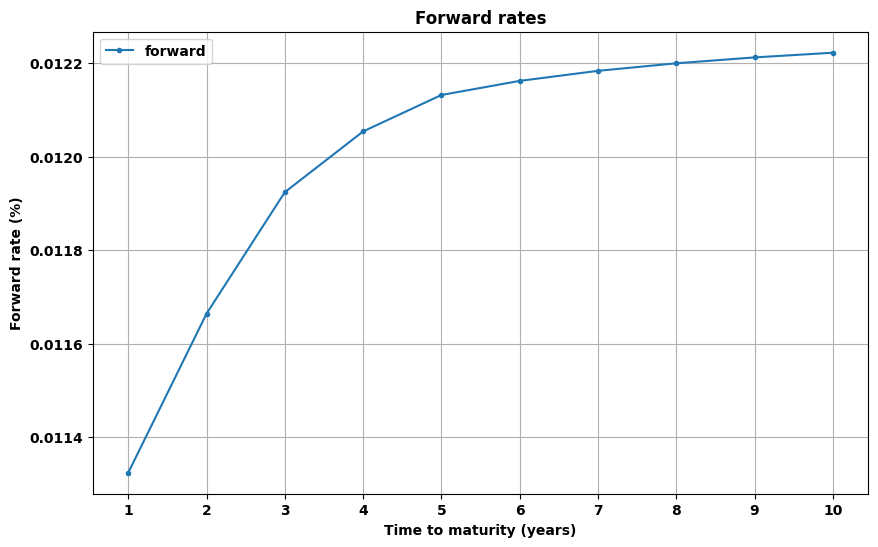

In [15]:
df = pd.DataFrame(spots, columns=['date', 'forward'])
df.set_index('date', inplace=True)
df.plot(
    title='Forward rates',
    figsize=(10, 6),
    grid=True,
    legend=True,
    xticks=range(1, 11),
    xlabel='Time to maturity (years)',
    ylabel='Forward rate (%)',
    style='.-',
)
df

,forward
date,
1,0.011324
2,0.012005
3,0.012444
4,0.012444
5,0.012444
6,0.012313
7,0.012313
8,0.012313
9,0.012313


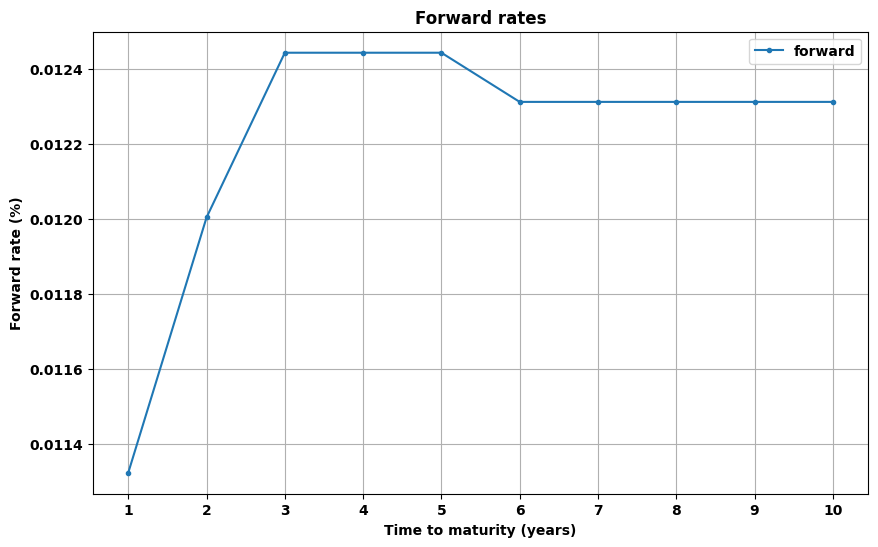

In [16]:
df = pd.DataFrame(forwards, columns=['date', 'forward'])
df.set_index('date', inplace=True)
df.plot(
    title='Forward rates',
    figsize=(10, 6),
    grid=True,
    legend=True,
    xticks=range(1, 11),
    xlabel='Time to maturity (years)',
    ylabel='Forward rate (%)',
    style='.-',
)
df

In [17]:
def make_fixed_bond(maturity, coupon, face=100.0):
    bschedule = ql.Schedule(
    today, maturity, ql.Period(ql.Annual), cal,
    ql.Following, ql.Following, ql.DateGeneration.Backward, end_of_month)


    bond = ql.FixedRateBond(
        settlement_days,
        face,
        bschedule,
        [coupon],
        ACTACT_ICMA,
        ql.Following,
        100.0) # redemption
    return bond


# Przykładowe serie
DS0726 = make_fixed_bond(ql.Date(25, ql.July, 2026), 0.025)
PS1029 = make_fixed_bond(ql.Date(25, ql.October, 2029), 0.0275)


engine = ql.DiscountingBondEngine(ql.YieldTermStructureHandle(curve))
for b in (DS0726, PS1029):
    b.setPricingEngine(engine)
    print("===", b.maturityDate(), "===")
    print("Clean:", b.cleanPrice())
    print("Dirty:", b.dirtyPrice())
    print("Accrued:", b.accruedAmount())
    # YTM (roczna kapitalizacja)
    clean_price = ql.SimpleQuote(b.cleanPrice())
    ytm = ytm = b.bondYield(ACTACT_ICMA, ql.Compounded, ql.Annual)
    print("YTM:", ytm)
    dur_mod = ql.BondFunctions.duration(
        b, ytm, ACTACT_ICMA, ql.Compounded, ql.Annual, ql.Duration.Modified)
    print("ModDuration:", dur_mod)
    dv01 = dur_mod * b.dirtyPrice() / 100.0
    print("DV01:", dv01)
    print("Convexity:", ql.BondFunctions.convexity(
        b, ytm, ACTACT_ICMA, ql.Compounded, ql.Annual))

=== July 27th, 2026 ===
Clean: 101.12308514621498
Dirty: 101.1505576736875
Accrued: 0.027472527472527375
YTM: 0.012401468431949617
ModDuration: 0.8900608396929346
DV01: 0.9003015029845091
Convexity: 1.671366287992638
=== October 25th, 2029 ===
Clean: 106.21113068615061
Dirty: 106.24135046637039
Accrued: 0.03021978021977567
YTM: 0.012074247062206271
ModDuration: 3.934875181132627
DV01: 4.180464531601341
Convexity: 19.75595584770589


In [18]:
ytm = b.bondYield(ACTACT_ICMA, ql.Compounded, ql.Annual)  # + ewentualnie accuracy, maxEval

In [19]:
pow(2,3)

8.0

In [20]:
settle = b.settlementDate()  # spójnie z evaluationDate i settlementDays
clean = b.cleanPrice()       # albo Twoja rynkowa cena clean

ytm = b.bondYield(
    ql.BondPrice(clean, ql.BondPrice.Clean),
    ACTACT_ICMA, ql.Compounded, ql.Annual,
    settle, 1.0e-10, 100, 0.05  # accuracy, maxEval, guess (opcjonalnie)
)

In [21]:
ytm

0.012074250254146757

In [22]:
schedule = ql.MakeSchedule(
    effectiveDate=ql.Date(7, ql.February, 2021),
    terminationDate=ql.Date(7, ql.February, 2026),
    frequency=ql.Annual,
    calendar=ql.Poland(),
    convention=ql.Following,
    backwards=True,
)

In [23]:
day_count = ql.ActualActual(ql.ActualActual.Bond)

fixed_coupons = ql.FixedRateLeg(
    schedule=schedule,
    couponRates=[0.03],
    dayCount=day_count,
    nominals=[1_000],
)

In [27]:
settlement_days = 2
issue_date = ql.Date(5, ql.February, 2021)

bond1 = ql.Bond(
    settlement_days,
    ql.TARGET(),
    issue_date,
    fixed_coupons,
)

In [25]:
data = []
for cf in bond1.cashflows():
    c = ql.as_coupon(cf)
    if c is not None:
        data.append((c.date(), c.nominal(), c.rate(), c.amount()))
    else:
        data.append((cf.date(), None, None, cf.amount()))

pd.DataFrame(
    data, columns=["date", "nominal", "rate", "amount"]
).style.format({"nominal": "{:.0f}", "rate": "{:.3%}", "amount": "{:.3f}"})

,date,nominal,rate,amount
0,"February 7th, 2022",1000,3.000%,30.000
1,"February 7th, 2023",1000,3.000%,30.000
2,"February 7th, 2024",1000,3.000%,30.000
3,"February 7th, 2025",1000,3.000%,30.000
4,"February 9th, 2026",1000,3.000%,30.000
5,"February 9th, 2026",nan,nan%,1000.000


In [28]:
price = ql.BondPrice(97.5, ql.BondPrice.Clean)
bond1.bondYield(price, day_count, ql.Compounded, ql.Semiannual)

0.0883007349038124